# Predictia pretului masinilor second-hand

**Curs:** Introduction to Machine Learning Using Python
**Modul:** Cand un model prezice numere: Regresia in practica

Acest notebook documenteaza intregul flux de lucru pentru predictia
pretului (`priceUSD`) unei masini second-hand, pe baza caracteristicilor
ei (marca, model, an, kilometraj, stare, combustibil etc.), folosind
setul de date `cars.csv`.

Structura notebook-ului:
1. Incarcare si explorare date (EDA)
2. Curatarea datelor
3. Ingineria caracteristicilor
4. Preprocesare
5. Antrenarea si compararea modelelor de regresie
6. Evaluarea si interpretarea rezultatelor
7. Concluzie

Codul reutilizeaza functiile din `src/` (data_cleaning.py,
feature_engineering.py, data_preprocessing.py), ca sa nu duplicam logica
intre notebook si scripturile de productie.

## 1. Import biblioteci si module proprii

In [29]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from data_cleaning import load_and_clean_data
from feature_engineering import add_features
from data_preprocessing import build_preprocessor, prepare_features_and_target


## 2. Incarcarea si explorarea datelor (EDA)

Incarcam datele brute si aruncam o privire generala: cate randuri/coloane
avem, ce tipuri de date, cate valori lipsa, si cum arata distributia
variabilei tinta (`priceUSD`).

In [30]:
df_raw = pd.read_csv("../data/cars.csv")

print(f"Numar de randuri: {len(df_raw)}")
print(f"Numar de coloane: {df_raw.shape[1]}")
display(df_raw.head())

print("\nTipuri de date:")
print(df_raw.dtypes)

print("\nValori lipsa pe coloane:")
print(df_raw.isnull().sum())


Numar de randuri: 56244
Numar de coloane: 12


,make,model,priceUSD,year,condition,mileage(kilometers),fuel_type,volume(cm3),color,transmission,drive_unit,segment
0,mazda,2,5500,2008,with mileage,162000.0,petrol,1500.0,burgundy,mechanics,front-wheel drive,B
1,mazda,2,5350,2009,with mileage,120000.0,petrol,1300.0,black,mechanics,front-wheel drive,B
2,mazda,2,7000,2009,with mileage,61000.0,petrol,1500.0,silver,auto,front-wheel drive,B
3,mazda,2,3300,2003,with mileage,265000.0,diesel,1400.0,white,mechanics,front-wheel drive,B
4,mazda,2,5200,2008,with mileage,97183.0,diesel,1400.0,gray,mechanics,front-wheel drive,B



Tipuri de date:
make                       str
model                      str
priceUSD                 int64
year                     int64
condition                  str
mileage(kilometers)    float64
fuel_type                  str
volume(cm3)            float64
color                      str
transmission               str
drive_unit                 str
segment                    str
dtype: object

Valori lipsa pe coloane:
make                      0
model                     0
priceUSD                  0
year                      0
condition                 0
mileage(kilometers)       0
fuel_type                 0
volume(cm3)              47
color                     0
transmission              0
drive_unit             1905
segment                5291
dtype: int64


### Observatii cheie din explorare

- **`priceUSD`** (variabila tinta): valori intre 48 si 235.235 USD, cu media
  in jur de 7400 USD - distributie puternic asimetrica (cateva masini de
  lux foarte scumpe "trag" media in sus fata de mediana).
- **`volume(cm3)`** lipseste la 47 de randuri - **exclusiv** la masinile
  electrice (`fuel_type == "electrocar"`), ceea ce are sens: masinile
  electrice nu au o capacitate a motorului in cm3.
- **`drive_unit`** lipseste la 1905 randuri si **`segment`** la 5291 randuri
  - probabil campuri optionale, nu completate de toti vanzatorii.
- **`condition`** are un impact urias asupra pretului mediu:
  - "with mileage" (masina functionala): ~7515 USD in medie
  - "with damage" (avariata): ~2721 USD in medie
  - "for parts" (pentru piese): ~596 USD in medie
- Exista valori extreme suspecte: masini cu an de fabricatie sub 1950,
  kilometraje peste 1.000.000 km, si preturi sub 100 USD - probabil erori
  de introducere a datelor sau anunturi test.

### Distributia variabilei tinta (priceUSD)

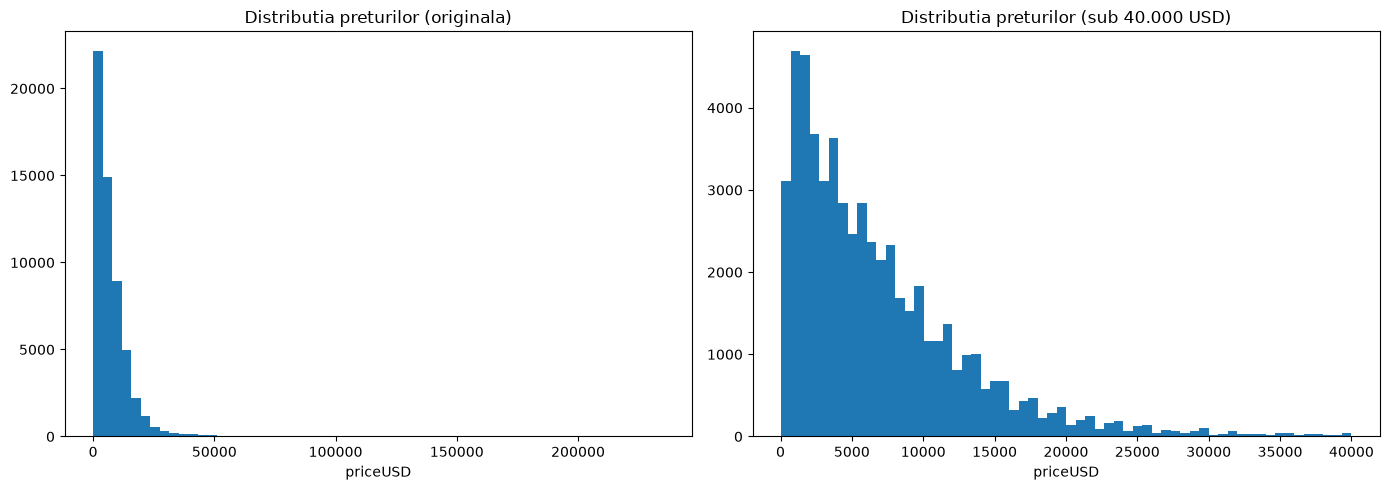

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_raw["priceUSD"], bins=60)
axes[0].set_title("Distributia preturilor (originala)")
axes[0].set_xlabel("priceUSD")

axes[1].hist(df_raw[df_raw["priceUSD"] < 40000]["priceUSD"], bins=60)
axes[1].set_title("Distributia preturilor (sub 40.000 USD)")
axes[1].set_xlabel("priceUSD")

plt.tight_layout()
plt.show()


### Pretul mediu in functie de starea masinii (condition)

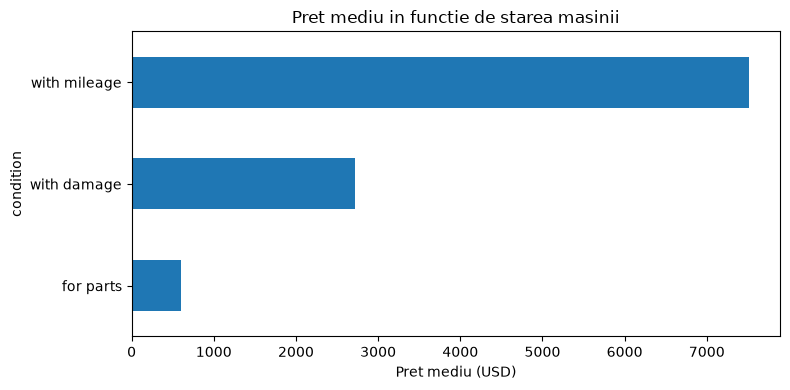

condition
for parts        596.405286
with damage     2721.089844
with mileage    7514.942038
Name: priceUSD, dtype: float64


In [32]:
condition_price = df_raw.groupby("condition")["priceUSD"].mean().sort_values()
condition_price.plot(kind="barh", figsize=(8, 4))
plt.title("Pret mediu in functie de starea masinii")
plt.xlabel("Pret mediu (USD)")
plt.tight_layout()
plt.show()

print(condition_price)


## 3. Curatarea datelor

Folosim functia `load_and_clean_data` din `data_cleaning.py`, care:
- redenumeste coloanele `mileage(kilometers)` -> `mileage_km` si
  `volume(cm3)` -> `volume_cm3`;
- completeaza `volume_cm3` cu 0 pentru masinile electrice;
- completeaza `drive_unit` si `segment` lipsa cu categoria `"unknown"`;
- elimina randurile cu an de fabricatie sub 1950, kilometraj peste
  1.000.000 km, si preturi sub 100 USD sau peste percentila 99.9
  (outlieri care ar distorsiona modelul de regresie).

In [33]:
df_clean = load_and_clean_data("../data/cars.csv")

print(f"Randuri inainte de curatare: {len(df_raw)}")
print(f"Randuri dupa curatare: {len(df_clean)}")
print(f"Randuri eliminate: {len(df_raw) - len(df_clean)}")

print("\nValori lipsa dupa curatare:")
print(df_clean.isnull().sum())


Randuri inainte de curatare: 56244
Randuri dupa curatare: 55815
Randuri eliminate: 429

Valori lipsa dupa curatare:
make            0
model           0
priceUSD        0
year            0
condition       0
mileage_km      0
fuel_type       0
volume_cm3      0
color           0
transmission    0
drive_unit      0
segment         0
dtype: int64


## 4. Ingineria caracteristicilor (Feature Engineering)

Adaugam caracteristici suplimentare, derivate din cele existente (vezi
`feature_engineering.py` pentru detalii complete):

- **car_age** - varsta masinii (2024 - year)
- **mileage_per_year** - kilometraj mediu pe an de utilizare
- **engine_volume_liters** - capacitatea motorului in litri (in loc de cm3)
- **is_newer_car** - indicator daca masina are cel mult 5 ani
- **is_high_mileage** - indicator daca kilometrajul depaseste 200.000 km
- **brand_model** - combinatie marca+model (grupata ulterior la
  preprocesare, pastrand doar cele mai frecvente 40 de combinatii, restul
  devenind "other" - altfel am avea 1000+ categorii distincte, majoritatea
  foarte rare).

In [34]:
df_features = add_features(df_clean)
display(df_features[["car_age", "mileage_per_year", "engine_volume_liters",
                      "is_newer_car", "is_high_mileage", "brand_model"]].head())


,car_age,mileage_per_year,engine_volume_liters,is_newer_car,is_high_mileage,brand_model
0,16,9529.411765,1.5,0,0,mazda_2
1,15,7500.000000,1.3,0,0,mazda_2
2,15,3812.500000,1.5,0,0,mazda_2
3,21,12045.454545,1.4,0,1,mazda_2
4,16,5716.647059,1.4,0,0,mazda_2


### Corelatia caracteristicilor numerice cu pretul

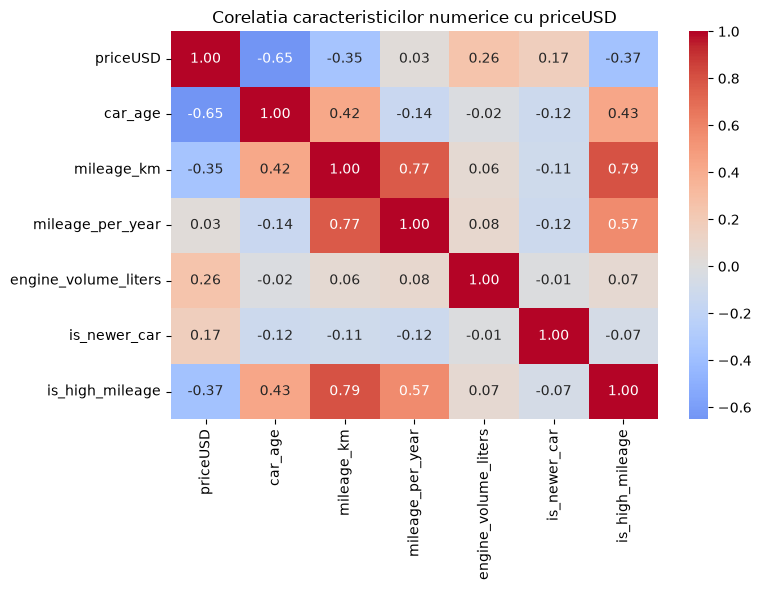

In [35]:
numeric_cols = ["priceUSD", "car_age", "mileage_km", "mileage_per_year",
                "engine_volume_liters", "is_newer_car", "is_high_mileage"]

corr = df_features[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corelatia caracteristicilor numerice cu priceUSD")
plt.tight_layout()
plt.show()


## 5. Preprocesarea datelor

Folosim `build_preprocessor()` din `data_preprocessing.py`:
- caracteristicile numerice sunt completate (mediana) si scalate
  (StandardScaler);
- caracteristicile categorice sunt completate (cea mai frecventa valoare)
  si codificate one-hot, cu `handle_unknown="ignore"` (astfel incat
  categoriile nevazute la antrenare sa nu blocheze predictia).

In [36]:
X, y = prepare_features_and_target(df_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Masini de antrenament: {len(X_train)}")
print(f"Masini de testare: {len(X_test)}")

preprocessor = build_preprocessor()
X_train_transformed = preprocessor.fit_transform(X_train)
print(f"Numar de caracteristici dupa preprocesare: {X_train_transformed.shape[1]}")


Masini de antrenament: 44652
Masini de testare: 11163
Numar de caracteristici dupa preprocesare: 175


## 6. Antrenarea si compararea modelelor

Comparam patru algoritmi de regresie, toti folosind exact acelasi
preprocessor si aceeasi impartire train/test, pentru o comparatie corecta:

- **Linear Regression** - simplu, rapid, usor de interpretat
- **Decision Tree Regressor** - captureaza relatii ne-liniare
- **Random Forest Regressor** - ansamblu de arbori, de obicei robust
- **Gradient Boosting Regressor** - ansamblu secvential, adesea foarte precis

Evaluam fiecare model cu MAE, MSE, RMSE si R².

In [37]:
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=60, max_depth=14, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
}

results = []
trained_pipelines = {}

for name, regressor in candidate_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", build_preprocessor()),
        ("regressor", regressor),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    trained_pipelines[name] = (pipeline, y_pred)

    print(f"{name}: MAE={mae:.2f}  RMSE={rmse:.2f}  R2={r2:.4f}")


Linear Regression: MAE=2446.50  RMSE=4425.40  R2=0.6734
Decision Tree Regressor: MAE=1405.20  RMSE=2781.04  R2=0.8710
Random Forest Regressor: MAE=1173.03  RMSE=2293.24  R2=0.9123
Gradient Boosting Regressor: MAE=1451.18  RMSE=2629.61  R2=0.8847


### Tabel comparativ

In [38]:
results_df = pd.DataFrame(results).sort_values(by="RMSE").reset_index(drop=True)
display(results_df)


,Model,MAE,MSE,RMSE,R2
0,Random Forest Regressor,1173.027731,5.258962e+06,2293.242735,0.912310
1,Gradient Boosting Regressor,1451.175026,6.914846e+06,2629.609488,0.884699
2,Decision Tree Regressor,1405.202858,7.734177e+06,2781.038911,0.871037
3,Linear Regression,2446.500417,1.958416e+07,4425.399675,0.673446


## 7. Evaluarea si interpretarea rezultatelor modelului castigator

Alegem modelul cu cel mai mic RMSE si analizam mai in detaliu erorile lui.

In [39]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline, best_y_pred = trained_pipelines[best_model_name]

print(f"Cel mai bun model: {best_model_name}")
print(f"MAE  = {results_df.iloc[0]['MAE']:.2f} USD")
print(f"RMSE = {results_df.iloc[0]['RMSE']:.2f} USD")
print(f"R2   = {results_df.iloc[0]['R2']:.4f}")


Cel mai bun model: Random Forest Regressor
MAE  = 1173.03 USD
RMSE = 2293.24 USD
R2   = 0.9123


### Exemple: pret real vs. pret estimat

In [40]:
sample_df = pd.DataFrame({
    "pret real": y_test.values,
    "pret estimat": np.round(best_y_pred).astype(int),
})
sample_df["eroare"] = (sample_df["pret real"] - sample_df["pret estimat"]).abs()
display(sample_df.sample(15, random_state=42))


,pret real,pret estimat,eroare
4132,16299,13997,2302
1160,9450,11380,1930
5391,2595,4094,1499
9695,200,316,116
10983,11500,9445,2055
10516,9350,8577,773
2407,9700,9683,17
573,8900,10513,1613
5910,800,790,10
7222,4480,4911,431


### Grafic: pret real vs. pret estimat

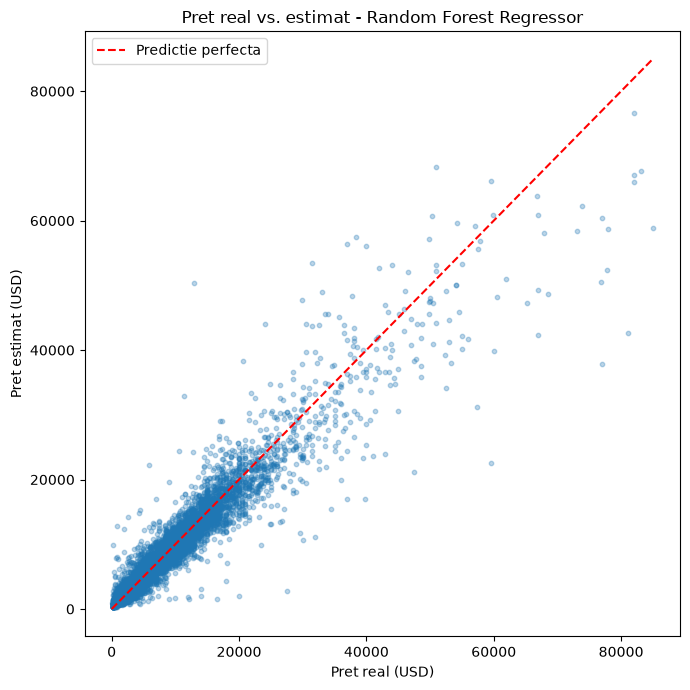

In [41]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_y_pred, alpha=0.3, s=10)
max_val = max(y_test.max(), best_y_pred.max())
plt.plot([0, max_val], [0, max_val], color="red", linestyle="--", label="Predictie perfecta")
plt.xlabel("Pret real (USD)")
plt.ylabel("Pret estimat (USD)")
plt.title(f"Pret real vs. estimat - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Salvarea modelului final

Modelul final e deja salvat de scriptul `src/model_comparison.py` in
`models/car_price_model.joblib`. Aici doar confirmam ca putem re-salva
acelasi pipeline din notebook, daca e nevoie.

In [42]:
import joblib
joblib.dump(best_pipeline, "../models/car_price_model.joblib")
print("Model salvat in ../models/car_price_model.joblib")


Model salvat in ../models/car_price_model.joblib


## 9. Concluzie

**Modelul cu cea mai buna performanta a fost: Random Forest Regressor**,
cu MAE = 1173 USD, RMSE = 2293 USD si R² = 0.9123 (explica ~91.2% din
variatia preturilor din setul de testare).

**Cum s-au comportat celelalte modele:**
- Gradient Boosting Regressor a fost al doilea cel mai bun (MAE = 1451,
  R² = 0.885) - foarte aproape de Random Forest, dar usor mai slab pe
  acest set de date cu hiperparametrii impliciti.
- Decision Tree Regressor a avut rezultate rezonabile (MAE = 1405,
  R² = 0.871), dar, fiind un singur arbore, e mai predispus la
  overfitting/varianta mare fata de ansamblul Random Forest.
- Linear Regression a ramas clar in urma (MAE = 2446, R² = 0.673) -
  relatia dintre caracteristici si pret nu este liniara (de exemplu,
  deprecierea unei masini in functie de varsta sau kilometraj nu e
  constanta), asa ca un model liniar simplu nu poate capta aceste
  tipare la fel de bine ca un ansamblu de arbori. In plus, Linear
  Regression a produs si cateva predictii cu preturi NEGATIVE pentru
  masini foarte vechi/uzate - o limitare clara a modelelor liniare pe
  acest tip de date, pe care modelele bazate pe arbori nu o au (nu pot
  extrapola sub cel mai mic pret vazut la antrenare).

**Ce caracteristici au avut impact:** `car_age`, `mileage_km` si
`condition` par sa aiba cel mai puternic efect asupra pretului (vizibil
si in graficul de corelatie si in diferenta mare de pret medie intre
"with mileage", "with damage" si "for parts"). Caracteristicile derivate
(`mileage_per_year`, `is_high_mileage`) au adaugat informatie
suplimentara utila mai ales pentru modelele bazate pe arbori.

**Modelul final ales pentru echipa: Random Forest Regressor**, pentru
ca are cel mai bun echilibru intre acuratete (cel mai mic RMSE si MAE)
si robustete (nu produce predictii absurde, precum preturi negative),
si generalizeaza mai bine decat un singur Decision Tree.

### Observatii si dileme intalnite pe parcurs
- Cea mai mare provocare a fost gestionarea coloanei `model`, care are
  peste 1000 de valori distincte - o codificare one-hot directa ar fi
  creat foarte multe coloane rare. Solutia aleasa a fost gruparea
  categoriilor `brand_model` (marca+model) sub eticheta "other" pentru
  toate combinatiile in afara celor mai frecvente 40.
- Alta observatie: eliminarea valorilor extreme (an de fabricatie sub
  1950, kilometraj peste 1.000.000 km, preturi sub 100 USD sau in topul
  0.1%) a fost o decizie importanta pentru stabilitatea modelelor -
  fara aceasta curatare, cateva masini de colectie foarte scumpe sau
  randuri clar eronate ar fi distorsionat semnificativ metricile.
- Ce as imbunatati intr-o versiune viitoare: as incerca optimizarea
  hiperparametrilor (GridSearchCV/RandomizedSearchCV) pentru Random
  Forest si Gradient Boosting, si as testa daca transformarea logaritmica
  a variabilei tinta (log(priceUSD)) imbunatateste stabilitatea
  modelelor liniare pe distributia asimetrica a preturilor.
